# BASS fire-spread relationships

This analysis uses BASS-II observations from `astroflame_formatted_cgs.csv`. It assumes every BASS sample is 10 cm long, calculates planform area as `sample_width_cm * 10`, and treats thickness separately. FSR is in cm/s.

The descriptive summaries below average observations within experiment IDs, while the predictor and its validation use every individual BASS observation and hold out complete experiment IDs. Initial oxygen is considered an input; final oxygen and oxygen drop are outcomes/diagnostics, not predictor inputs.

In [9]:
from pathlib import Path

import numpy as np
import pandas as pd

input_name = "astroflame_formatted_cgs.csv"
candidate_dirs = [Path.cwd(), Path.cwd() / "elig-data"]
input_path = next(
    (directory / input_name for directory in candidate_dirs if (directory / input_name).is_file()),
    None,
)
if input_path is None:
    raise FileNotFoundError(f"Could not find {input_name} in the current folder or its elig-data subfolder.")

data_dir = input_path.parent
all_data = pd.read_csv(input_path)
required_columns = {
    "dataset",
    "experiment_id",
    "observation_id",
    "thickness_cm",
    "sample_width_cm",
    "fsr_cm_s",
    "airflow_cm_s",
    "oxygen_initial_pct",
    "oxygen_final_pct",
    "burning_sides",
}
missing_columns = required_columns.difference(all_data.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

bass = all_data[all_data["dataset"].str.contains("BASS", case=False, na=False)].copy()
if bass.empty:
    raise ValueError("No BASS observations were found in the formatted CSV.")

# The source does not record BASS length in each row; use the stated 10 cm assumption here.
bass["sample_length_cm"] = 10.0
bass["surface_area_cm2"] = bass["sample_width_cm"] * bass["sample_length_cm"]
bass["fsr_cm_s"] = pd.to_numeric(bass["fsr_cm_s"], errors="raise")

print(f"BASS observations: {len(bass)}")
print(f"BASS experiments: {bass['experiment_id'].nunique()}")
print("Assumed sample length: 10.0 cm")
print("Surface area values (cm^2):", sorted(bass["surface_area_cm2"].dropna().unique()))
print("Thickness values (cm):", sorted(bass["thickness_cm"].dropna().unique()))

BASS observations: 39
BASS experiments: 18
Assumed sample length: 10.0 cm
Surface area values (cm^2): [np.float64(12.0), np.float64(22.0)]
Thickness values (cm): [np.float64(0.1), np.float64(0.2), np.float64(0.3), np.float64(0.4), np.float64(0.5)]


In [10]:
group_keys = ["dataset", "experiment_id"]
experiment_fields = [
    "sample_width_cm",
    "surface_area_cm2",
    "thickness_cm",
    "oxygen_initial_pct",
    "oxygen_final_pct",
    "burning_sides",
]
for column in experiment_fields:
    distinct_values = bass.groupby(group_keys, dropna=False)[column].nunique(dropna=True)
    if distinct_values.gt(1).any():
        raise ValueError(f"{column} varies within an experiment; it cannot be summarized as a test-level value.")

experiment_means = (
    bass.groupby(group_keys, as_index=False, dropna=False)
    .agg(
        mean_fsr_cm_s=("fsr_cm_s", "mean"),
        surface_area_cm2=("surface_area_cm2", "first"),
        sample_width_cm=("sample_width_cm", "first"),
        thickness_cm=("thickness_cm", "first"),
        oxygen_initial_pct=("oxygen_initial_pct", "first"),
        oxygen_final_pct=("oxygen_final_pct", "first"),
        burning_sides=("burning_sides", "first"),
        segment_count=("fsr_cm_s", "count"),
    )
)

def simple_relationship(data, predictor):
    pair = data[[predictor, "mean_fsr_cm_s"]].dropna()
    if len(pair) < 3 or pair[predictor].nunique() < 2:
        return None
    x = pair[predictor].to_numpy(dtype=float)
    y = pair["mean_fsr_cm_s"].to_numpy(dtype=float)
    slope, intercept = np.polyfit(x, y, 1)
    predicted = intercept + slope * x
    total = ((y - y.mean()) ** 2).sum()
    r_squared = 1 - ((y - predicted) ** 2).sum() / total if total else np.nan
    correlations = pair.corr(method="pearson").iloc[0, 1], pair.corr(method="spearman").iloc[0, 1]
    return {
        "predictor": predictor,
        "n_experiments": len(pair),
        "pearson_r": correlations[0],
        "spearman_rho": correlations[1],
        "slope": slope,
        "intercept": intercept,
        "r_squared": r_squared,
        "equation": f"FSR = {intercept:.4g} + ({slope:.4g} * {predictor})",
    }

predictors = [
    "surface_area_cm2",
    "thickness_cm",
    "oxygen_initial_pct",
]
correlation_summary = pd.DataFrame(
    [result for column in predictors if (result := simple_relationship(experiment_means, column)) is not None]
)
print("Experiment-mean FSR relationships (FSR in cm/s):")
print(correlation_summary.to_string(index=False, float_format=lambda value: f"{value:.4g}"))

model = experiment_means[["mean_fsr_cm_s", "surface_area_cm2", "thickness_cm"]].dropna()
design = np.column_stack(
    [np.ones(len(model)), model[["surface_area_cm2", "thickness_cm"]].to_numpy(dtype=float)]
)
target = model["mean_fsr_cm_s"].to_numpy(dtype=float)
coefficients = np.linalg.lstsq(design, target, rcond=None)[0]
predicted = design @ coefficients
model_r_squared = 1 - ((target - predicted) ** 2).sum() / ((target - target.mean()) ** 2).sum()
print(
    "\nExploratory two-factor equation: "
    f"mean FSR = {coefficients[0]:.4g} + ({coefficients[1]:.4g} * surface_area_cm2) "
    f"+ ({coefficients[2]:.4g} * thickness_cm); R^2 = {model_r_squared:.3f}; n = {len(model)} experiments"
)

flow = bass[["dataset", "experiment_id", "airflow_cm_s", "fsr_cm_s"]].dropna().copy()
repeated_tests = flow.groupby(group_keys)["fsr_cm_s"].transform("size").ge(2)
flow = flow.loc[repeated_tests].copy()
for column in ["airflow_cm_s", "fsr_cm_s"]:
    flow[f"{column}_deviation"] = flow[column] - flow.groupby(group_keys)[column].transform("mean")
flow_pair = flow[["airflow_cm_s_deviation", "fsr_cm_s_deviation"]]
flow_pearson = flow_pair.corr(method="pearson").iloc[0, 1]
flow_spearman = flow_pair.corr(method="spearman").iloc[0, 1]
flow_x = flow["airflow_cm_s_deviation"]
flow_y = flow["fsr_cm_s_deviation"]
flow_slope = (flow_x * flow_y).sum() / (flow_x**2).sum()
print(
    f"\nWithin-experiment airflow association: Pearson r = {flow_pearson:.3f}, "
    f"Spearman rho = {flow_spearman:.3f}, slope = {flow_slope:.4g} (cm/s FSR per cm/s airflow), "
    f"n = {len(flow)} segments across {flow[group_keys].drop_duplicates().shape[0]} repeated experiments."
)

burning_sides_summary = (
    experiment_means.groupby("burning_sides")["mean_fsr_cm_s"]
    .agg(n_experiments="count", mean_fsr_cm_s="mean", median_fsr_cm_s="median")
    .reset_index()
)
print("\nDescriptive FSR by burning sides (experiment means):")
print(burning_sides_summary.to_string(index=False, float_format=lambda value: f"{value:.4g}"))
for column in ["material", "geometry", "flow_direction"]:
    print(f"BASS {column} values:", bass[column].dropna().unique().tolist())

Experiment-mean FSR relationships (FSR in cm/s):
         predictor  n_experiments  pearson_r  spearman_rho     slope  intercept  r_squared                                           equation
  surface_area_cm2             18   0.002296      -0.01196 1.405e-06   0.004619  5.274e-06    FSR = 0.004619 + (1.405e-06 * surface_area_cm2)
      thickness_cm             18    -0.7291       -0.7179  -0.01443   0.009217     0.5316         FSR = 0.009217 + (-0.01443 * thickness_cm)
oxygen_initial_pct             18     0.2058        0.4946 0.0003686  -0.002771    0.04235 FSR = -0.002771 + (0.0003686 * oxygen_initial_pct)

Exploratory two-factor equation: mean FSR = 0.008573 + (3.491e-05 * surface_area_cm2) + (-0.01452 * thickness_cm); R^2 = 0.535; n = 18 experiments

Within-experiment airflow association: Pearson r = 0.679, Spearman rho = 0.770, slope = 0.0002913 (cm/s FSR per cm/s airflow), n = 34 segments across 13 repeated experiments.

Descriptive FSR by burning sides (experiment means):
 burn

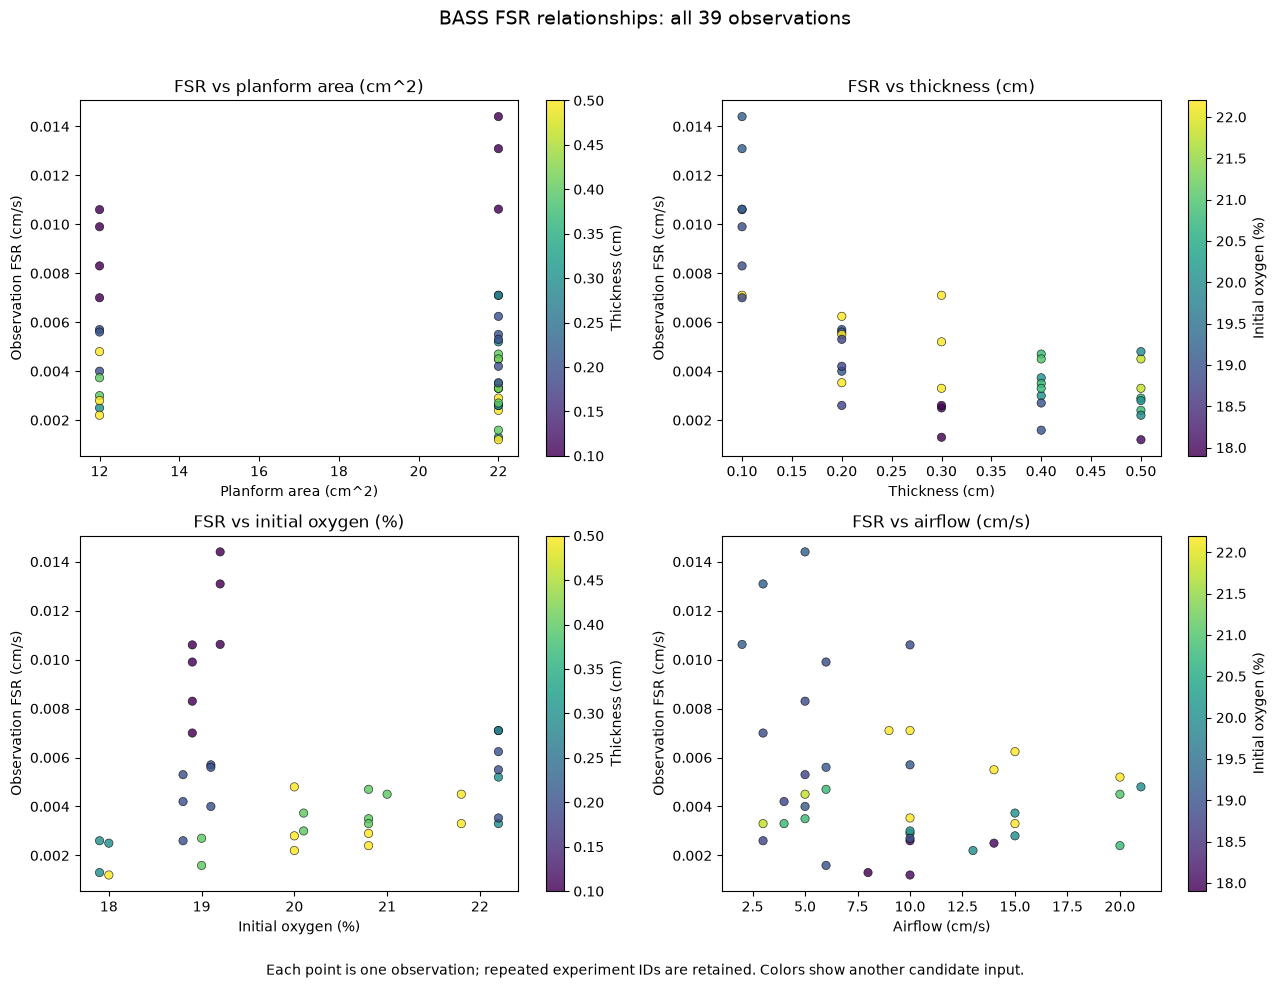

Saved all-observation chart: bass_fsr_geometry_oxygen.png


In [11]:
import matplotlib.pyplot as plt

chart_data = bass.dropna(
    subset=[
        "surface_area_cm2",
        "thickness_cm",
        "oxygen_initial_pct",
        "airflow_cm_s",
        "fsr_cm_s",
    ]
).copy()
if len(chart_data) != len(bass):
    raise ValueError("Some BASS observations are missing chart values; inspect before plotting.")

fig, axes = plt.subplots(2, 2, figsize=(13, 10))
chart_specs = [
    (axes[0, 0], "surface_area_cm2", "thickness_cm", "Planform area (cm^2)", "Thickness (cm)"),
    (axes[0, 1], "thickness_cm", "oxygen_initial_pct", "Thickness (cm)", "Initial oxygen (%)"),
    (axes[1, 0], "oxygen_initial_pct", "thickness_cm", "Initial oxygen (%)", "Thickness (cm)"),
    (axes[1, 1], "airflow_cm_s", "oxygen_initial_pct", "Airflow (cm/s)", "Initial oxygen (%)"),
]
for axis, x_column, color_column, x_label, color_label in chart_specs:
    points = axis.scatter(
        chart_data[x_column],
        chart_data["fsr_cm_s"],
        c=chart_data[color_column],
        cmap="viridis",
        edgecolor="black",
        linewidth=0.45,
        alpha=0.82,
    )
    axis.set(
        title=f"FSR vs {x_label.lower()}",
        xlabel=x_label,
        ylabel="Observation FSR (cm/s)",
    )
    fig.colorbar(points, ax=axis, label=color_label)

fig.suptitle(f"BASS FSR relationships: all {len(chart_data)} observations", fontsize=14)
fig.text(
    0.5,
    0.015,
    "Each point is one observation; repeated experiment IDs are retained. Colors show another candidate input.",
    ha="center",
)
fig.tight_layout(rect=[0, 0.04, 1, 0.96])
geometry_oxygen_chart = data_dir / "bass_fsr_geometry_oxygen.png"
fig.savefig(geometry_oxygen_chart, dpi=180, bbox_inches="tight")
plt.show()
print(f"Saved all-observation chart: {geometry_oxygen_chart.name}")

## How to read these results

- Planform area is width times the assumed 10 cm length. Width and area have only two observed values, so their independent effects are difficult to estimate.
- The relationship chart shows all BASS observation rows rather than experiment means. Repeated experiment IDs are retained.
- The predictive model uses all observation rows and validates by holding out complete experiment IDs. This prevents rows from one test from appearing in both training and validation.
- Initial oxygen is an input. Final oxygen and oxygen drop are outcomes/diagnostics only; they are not used in the predictive equation.
- BASS material, geometry, and flow direction do not vary in this dataset, so their independent effects cannot be estimated here.

## All-observation BASS FSR predictor

This analysis uses all 39 BASS observation rows across 18 experiment IDs. Validation holds out one whole ID at a time, keeping rows from the same test together. Models are compared using row-weighted RMSE and equal-ID-weighted RMSE; equal-ID RMSE avoids letting IDs with more rows dominate.

For prediction, `oxygen_initial_pct` is an input. `oxygen_drop_pp = oxygen_initial_pct - oxygen_final_pct` is calculated and reported only as an outcome/diagnostic; final oxygen is not used by either predictor. Repeated experiment IDs are marked as possible relights based on your explanation, but the data does not identify which exact row followed a relight.

The notebook compares an initial-oxygen model with a second model that also includes airflow, using the same grouped validation folds. Area is tested as `sample_width_cm * 10 cm`, with thickness separate. Use predictions only within the observed input ranges and treat associations as exploratory, not causal.

Grouped leave-one-experiment-ID-out validation (lower RMSE is better):
                                                              model  uses_initial_oxygen  row_weighted_rmse_cm_s  equal_id_rmse_cm_s
                                              Power: thickness only                False               0.0020106           0.0020298
                                  Power: thickness + initial oxygen                 True               0.0020020           0.0020768
                                         Power: thickness + airflow                False               0.0020595           0.0020825
                        Power: thickness + airflow + initial oxygen                 True               0.0020374           0.0021106
                 Power: thickness + area + airflow + initial oxygen                 True               0.0022615           0.0022851
Power: thickness + airflow + initial oxygen + possible-relight flag                 True               0.0021828           0.002374

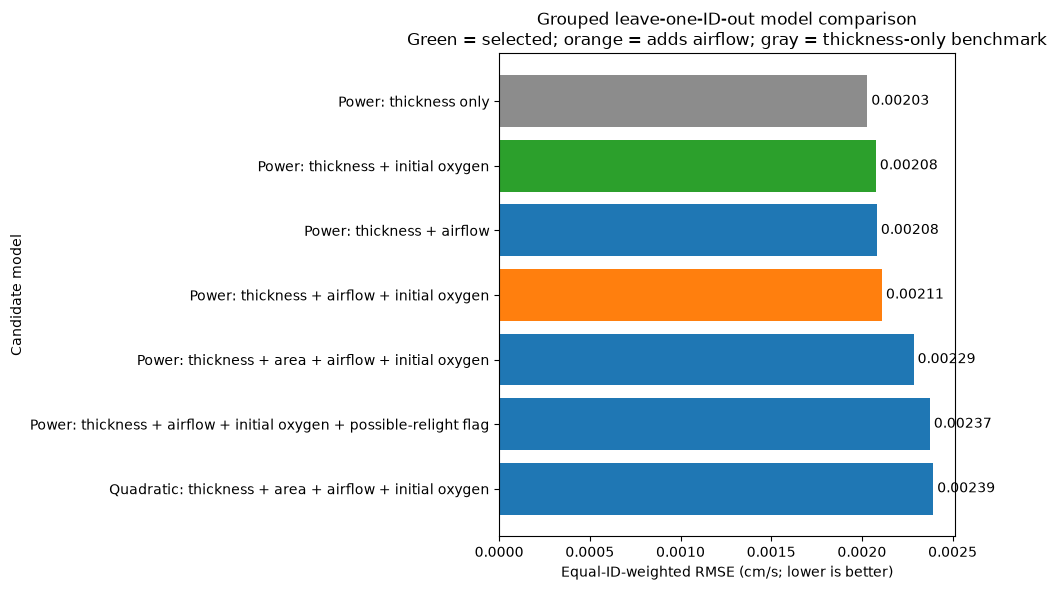

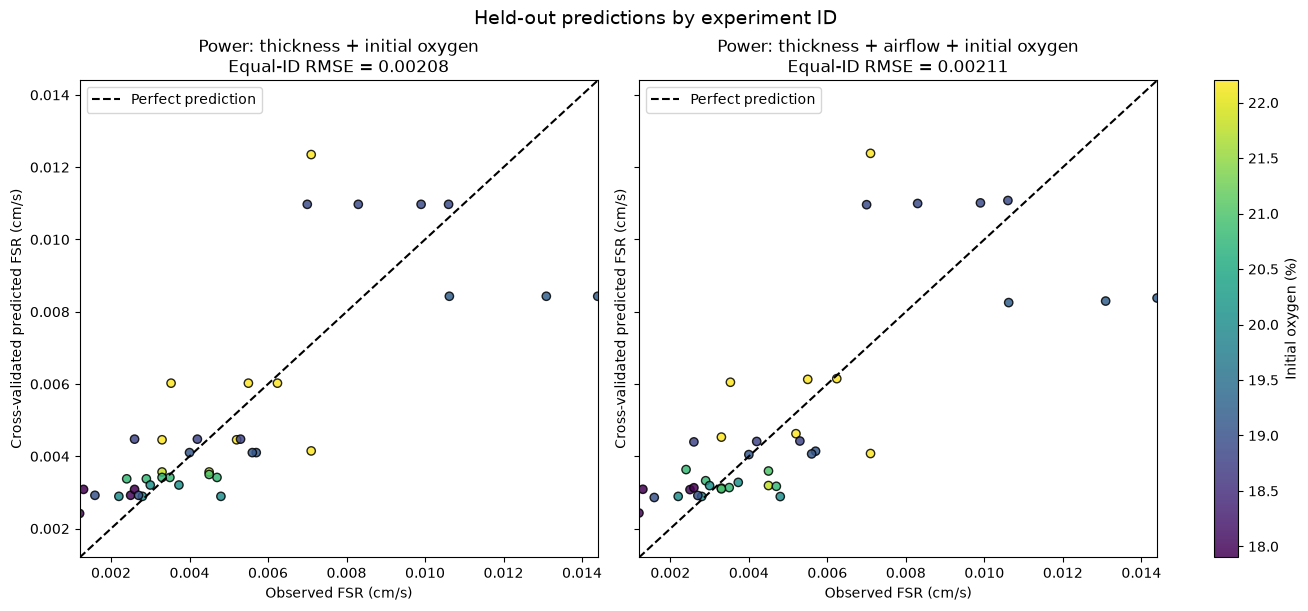

Saved current-statistics charts: bass_fsr_grouped_cv_model_comparison.png and bass_fsr_cross_validated_predictions.png (with/without airflow)


In [12]:
group_keys = ["dataset", "experiment_id"]
bass["oxygen_drop_pp"] = bass["oxygen_initial_pct"] - bass["oxygen_final_pct"]
bass["possible_relit_group"] = (
    bass.groupby(group_keys, dropna=False)["experiment_id"].transform("size").gt(1)
)
bass["validation_group"] = bass[group_keys].astype(str).agg(" | ".join, axis=1)

model_columns = [
    "fsr_cm_s",
    "thickness_cm",
    "airflow_cm_s",
    "surface_area_cm2",
    "oxygen_initial_pct",
    "oxygen_final_pct",
]
if bass[model_columns].isna().any().any():
    raise ValueError("Some BASS observations are missing model or oxygen values; inspect before modeling.")
if not np.isfinite(bass[model_columns].to_numpy(dtype=float)).all():
    raise ValueError("BASS model inputs contain non-finite values.")
if (bass["thickness_cm"] <= 0).any():
    raise ValueError("Thickness must be positive for the power-law model.")


def prediction_design(data, shape, features, exponent=None):
    thickness = data["thickness_cm"].to_numpy(dtype=float)
    columns = [np.ones(len(data))]
    if shape == "power":
        columns.append(thickness**exponent)
    elif shape == "quadratic":
        columns.extend([thickness, thickness**2])
    elif shape == "linear":
        columns.append(thickness)
    else:
        raise ValueError(f"Unsupported model shape: {shape}")
    columns.extend(data[feature].to_numpy(dtype=float) for feature in features)
    return np.column_stack(columns)


def fit_candidate(data, shape, features):
    target_values = data["fsr_cm_s"].to_numpy(dtype=float)

    def fit_at_exponent(exponent):
        design_matrix = prediction_design(data, shape, features, exponent)
        coefficients = np.linalg.lstsq(design_matrix, target_values, rcond=None)[0]
        residual_sum = np.sum((target_values - design_matrix @ coefficients) ** 2)
        return residual_sum, coefficients

    if shape != "power":
        _, coefficients = fit_at_exponent(None)
        return None, coefficients

    lower, upper = -5.0, 5.0
    ratio = (np.sqrt(5) - 1) / 2
    left = upper - ratio * (upper - lower)
    right = lower + ratio * (upper - lower)
    left_error, _ = fit_at_exponent(left)
    right_error, _ = fit_at_exponent(right)
    for _ in range(100):
        if left_error < right_error:
            upper, right, right_error = right, left, left_error
            left = upper - ratio * (upper - lower)
            left_error, _ = fit_at_exponent(left)
        else:
            lower, left, left_error = left, right, right_error
            right = lower + ratio * (upper - lower)
            right_error, _ = fit_at_exponent(right)
    exponent = (lower + upper) / 2
    _, coefficients = fit_at_exponent(exponent)
    return exponent, coefficients


candidate_models = [
    ("Power: thickness only", "power", []),
    ("Power: thickness + airflow", "power", ["airflow_cm_s"]),
    ("Power: thickness + initial oxygen", "power", ["oxygen_initial_pct"]),
    (
        "Power: thickness + airflow + initial oxygen",
        "power",
        ["airflow_cm_s", "oxygen_initial_pct"],
    ),
    (
        "Power: thickness + area + airflow + initial oxygen",
        "power",
        ["surface_area_cm2", "airflow_cm_s", "oxygen_initial_pct"],
    ),
    (
        "Power: thickness + airflow + initial oxygen + possible-relight flag",
        "power",
        ["airflow_cm_s", "oxygen_initial_pct", "possible_relit_group"],
    ),
    (
        "Quadratic: thickness + area + airflow + initial oxygen",
        "quadratic",
        ["surface_area_cm2", "airflow_cm_s", "oxygen_initial_pct"],
    ),
]

group_ids = bass["validation_group"].unique()
validation_rows = []
cv_predictions_by_model = {}
cv_actuals_by_model = {}
cv_oxygen_by_model = {}
for model_name, shape, features in candidate_models:
    residuals = []
    group_mean_squared_errors = []
    model_predictions = []
    model_actuals = []
    model_oxygen = []
    for held_out_group in group_ids:
        training = bass.loc[bass["validation_group"] != held_out_group]
        validation = bass.loc[bass["validation_group"] == held_out_group]
        exponent, coefficients = fit_candidate(training, shape, features)
        design_matrix = prediction_design(validation, shape, features, exponent)
        group_actuals = validation["fsr_cm_s"].to_numpy(dtype=float)
        group_predictions = design_matrix @ coefficients
        group_residuals = group_actuals - group_predictions
        residuals.extend(group_residuals.tolist())
        model_actuals.extend(group_actuals.tolist())
        model_predictions.extend(group_predictions.tolist())
        model_oxygen.extend(validation["oxygen_initial_pct"].to_numpy(dtype=float).tolist())
        group_mean_squared_errors.append(np.mean(group_residuals**2))
    cv_actuals_by_model[model_name] = np.asarray(model_actuals)
    cv_predictions_by_model[model_name] = np.asarray(model_predictions)
    cv_oxygen_by_model[model_name] = np.asarray(model_oxygen)
    validation_rows.append(
        {
            "model": model_name,
            "uses_initial_oxygen": "oxygen_initial_pct" in features,
            "row_weighted_rmse_cm_s": np.sqrt(np.mean(np.asarray(residuals) ** 2)),
            "equal_id_rmse_cm_s": np.sqrt(np.mean(group_mean_squared_errors)),
        }
    )

model_validation = pd.DataFrame(validation_rows).sort_values("equal_id_rmse_cm_s")
print("Grouped leave-one-experiment-ID-out validation (lower RMSE is better):")
print(model_validation.to_string(index=False, float_format=lambda value: f"{value:.7f}"))
oxygen_models = model_validation.loc[model_validation["uses_initial_oxygen"]]
best_model_name = oxygen_models.iloc[0]["model"]
best_model_spec = next(item for item in candidate_models if item[0] == best_model_name)
_, best_shape, best_features = best_model_spec
best_exponent, best_coefficients = fit_candidate(bass, best_shape, best_features)

airflow_model_name = "Power: thickness + airflow + initial oxygen"
airflow_model_spec = next(item for item in candidate_models if item[0] == airflow_model_name)
_, airflow_shape, airflow_features = airflow_model_spec
airflow_exponent, airflow_coefficients = fit_candidate(bass, airflow_shape, airflow_features)
airflow_rmse = float(
    model_validation.loc[
        model_validation["model"] == airflow_model_name, "equal_id_rmse_cm_s"
    ].iloc[0]
)

sizes_per_id = bass.groupby(group_keys, dropna=False).size()
repeated_id_count = int(sizes_per_id.gt(1).sum())
rows_in_repeated_ids = int(sizes_per_id.loc[sizes_per_id.gt(1)].sum())
print(
    f"\nUsed {len(bass)} BASS observations across {len(group_ids)} experiment IDs; "
    f"{repeated_id_count} IDs have multiple rows ({rows_in_repeated_ids} rows total)."
)
print(
    f"Outcome-only oxygen drop range: {bass['oxygen_drop_pp'].min():.1f} to "
    f"{bass['oxygen_drop_pp'].max():.1f} percentage points."
)

feature_labels = {
    "airflow_cm_s": "airflow_cm_s",
    "oxygen_initial_pct": "oxygen_initial_pct",
    "surface_area_cm2": "surface_area_cm2",
    "possible_relit_group": "possible_relit_group",
}
equation_terms = [f"{best_coefficients[0]:.8g}"]
if best_shape == "power":
    equation_terms.append(
        f"({best_coefficients[1]:.8g} * thickness_cm^{best_exponent:.4f})"
    )
    coefficient_offset = 2
elif best_shape == "quadratic":
    equation_terms.extend(
        [
            f"({best_coefficients[1]:.8g} * thickness_cm)",
            f"({best_coefficients[2]:.8g} * thickness_cm^2)",
        ]
    )
    coefficient_offset = 3
else:
    equation_terms.append(f"({best_coefficients[1]:.8g} * thickness_cm)")
    coefficient_offset = 2
for offset, feature in enumerate(best_features, start=coefficient_offset):
    equation_terms.append(f"({best_coefficients[offset]:.8g} * {feature_labels[feature]})")
print(f"\nSelected from models using initial oxygen: {best_model_name}")
print("Estimated observation-level FSR (cm/s) = " + " + ".join(equation_terms))
benchmark_rmse = float(
    model_validation.loc[
        model_validation["model"] == "Power: thickness only", "equal_id_rmse_cm_s"
    ].iloc[0]
)
selected_rmse = float(
    model_validation.loc[
        model_validation["model"] == best_model_name, "equal_id_rmse_cm_s"
    ].iloc[0]
)
print(
    f"Equal-ID CV RMSE: {selected_rmse:.7f} cm/s; "
    f"thickness-only benchmark: {benchmark_rmse:.7f} cm/s."
)

input_ranges = {
    "thickness_cm": (float(bass["thickness_cm"].min()), float(bass["thickness_cm"].max())),
    "oxygen_initial_pct": (
        float(bass["oxygen_initial_pct"].min()),
        float(bass["oxygen_initial_pct"].max()),
    ),
    "airflow_cm_s": (float(bass["airflow_cm_s"].min()), float(bass["airflow_cm_s"].max())),
}


def predict_bass_fsr(thickness_cm, oxygen_initial_pct):
    values = {
        "thickness_cm": float(thickness_cm),
        "oxygen_initial_pct": float(oxygen_initial_pct),
    }
    for name, value in values.items():
        lower, upper = input_ranges[name]
        if not np.isfinite(value) or not lower <= value <= upper:
            raise ValueError(f"{name} must be finite and within the observed range {lower} to {upper}.")
    row = pd.DataFrame([values])
    missing_features = set(best_features).difference(row.columns)
    if missing_features:
        raise ValueError(f"The selected model also requires inputs: {sorted(missing_features)}")
    design_matrix = prediction_design(row, best_shape, best_features, best_exponent)
    estimate = float((design_matrix @ best_coefficients)[0])
    if estimate <= 0:
        raise ValueError("This input combination gives a non-positive FSR estimate; do not extrapolate.")
    return estimate


def predict_bass_fsr_with_airflow(thickness_cm, oxygen_initial_pct, airflow_cm_s):
    values = {
        "thickness_cm": float(thickness_cm),
        "oxygen_initial_pct": float(oxygen_initial_pct),
        "airflow_cm_s": float(airflow_cm_s),
    }
    for name, value in values.items():
        lower, upper = input_ranges[name]
        if not np.isfinite(value) or not lower <= value <= upper:
            raise ValueError(f"{name} must be finite and within the observed range {lower} to {upper}.")
    row = pd.DataFrame([values])
    design_matrix = prediction_design(row, airflow_shape, airflow_features, airflow_exponent)
    estimate = float((design_matrix @ airflow_coefficients)[0])
    if estimate <= 0:
        raise ValueError("This input combination gives a non-positive FSR estimate; do not extrapolate.")
    return estimate


print(
    "Input ranges (thickness cm, initial oxygen %, airflow cm/s): "
    f"{input_ranges}. Oxygen drop and final oxygen are not predictor inputs."
)
print(
    "Example prediction at median observed inputs: "
    f"{predict_bass_fsr(bass['thickness_cm'].median(), bass['oxygen_initial_pct'].median()):.6g} cm/s"
)
print("Possible-relight flag is not used by the selected model.")
airflow_equation = (
    f"{airflow_coefficients[0]:.8g} "
    f"+ ({airflow_coefficients[1]:.8g} * thickness_cm^{airflow_exponent:.4f}) "
    f"+ ({airflow_coefficients[2]:.8g} * airflow_cm_s) "
    f"+ ({airflow_coefficients[3]:.8g} * oxygen_initial_pct)"
)
print(
    "Second model including airflow: FSR = "
    f"{airflow_equation}; equal-ID CV RMSE = {airflow_rmse:.7f} cm/s."
)
print(
    "Airflow model example prediction at median observed inputs: "
    f"{predict_bass_fsr_with_airflow(bass['thickness_cm'].median(), bass['oxygen_initial_pct'].median(), bass['airflow_cm_s'].median()):.6g} cm/s"
)

selected_cv_predictions = cv_predictions_by_model[best_model_name]
selected_cv_actuals = cv_actuals_by_model[best_model_name]
selected_cv_oxygen = cv_oxygen_by_model[best_model_name]

fig, axis = plt.subplots(figsize=(10, 6))
validation_plot = model_validation.sort_values("equal_id_rmse_cm_s", ascending=True)
bar_colors = [
    "tab:green"
    if name == best_model_name
    else "tab:orange"
    if name == airflow_model_name
    else "0.55"
    if name == "Power: thickness only"
    else "tab:blue"
    for name in validation_plot["model"]
]
bars = axis.barh(
    validation_plot["model"],
    validation_plot["equal_id_rmse_cm_s"],
    color=bar_colors,
)
axis.invert_yaxis()
axis.set(
    title=(
        "Grouped leave-one-ID-out model comparison\n"
        "Green = selected; orange = adds airflow; gray = thickness-only benchmark"
    ),
    xlabel="Equal-ID-weighted RMSE (cm/s; lower is better)",
    ylabel="Candidate model",
)
for bar, value in zip(bars, validation_plot["equal_id_rmse_cm_s"]):
    axis.text(value, bar.get_y() + bar.get_height() / 2, f" {value:.5f}", va="center")
fig.tight_layout()
validation_chart = data_dir / "bass_fsr_grouped_cv_model_comparison.png"
fig.savefig(validation_chart, dpi=180, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True, sharey=True, constrained_layout=True)
compared_models = [best_model_name, airflow_model_name]
all_values = np.concatenate(
    [
        cv_actuals_by_model[name]
        for name in compared_models
    ]
    + [
        cv_predictions_by_model[name]
        for name in compared_models
    ]
)
plot_limits = [float(all_values.min()), float(all_values.max())]
for axis, model_name in zip(axes, compared_models):
    actual = cv_actuals_by_model[model_name]
    predicted = cv_predictions_by_model[model_name]
    oxygen = cv_oxygen_by_model[model_name]
    points = axis.scatter(
        actual,
        predicted,
        c=oxygen,
        cmap="viridis",
        edgecolor="black",
        alpha=0.85,
    )
    model_rmse = float(
        model_validation.loc[
            model_validation["model"] == model_name, "equal_id_rmse_cm_s"
        ].iloc[0]
    )
    axis.plot(plot_limits, plot_limits, color="black", linestyle="--", label="Perfect prediction")
    axis.set(
        xlim=plot_limits,
        ylim=plot_limits,
        title=f"{model_name}\nEqual-ID RMSE = {model_rmse:.5f}",
        xlabel="Observed FSR (cm/s)",
        ylabel="Cross-validated predicted FSR (cm/s)",
    )
    axis.legend()
fig.colorbar(points, ax=axes, label="Initial oxygen (%)")
fig.suptitle("Held-out predictions by experiment ID", fontsize=14)
prediction_chart = data_dir / "bass_fsr_cross_validated_predictions.png"
fig.savefig(prediction_chart, dpi=180, bbox_inches="tight")
plt.show()
print(
    "Saved current-statistics charts: "
    f"{validation_chart.name} and {prediction_chart.name} (with/without airflow)"
)
